# Multi-Factor Equity Screener

This notebook walks through the pipeline in `src/`: rank stocks on five factor categories (12 metrics), then backtest the price-based factors. All logic lives in the package; the notebook only calls it.

It runs the 50-stock test set so it finishes in a few minutes. To use the full S&P 500, set `UNIVERSE = "sp500"` in the setup cell (the first download takes much longer).

Limitations: yfinance fundamentals are current values, not point-in-time, so the historical backtest uses price factors only (12-1 momentum, 6-month momentum, 60-day volatility and beta). The universe is today's tickers, which builds in survivorship bias. Sharpe ratios use a 0% risk-free rate.

The saved outputs below come from a fresh download with prices ending 5 Oct 2026. Yahoo revises adjusted prices and fundamentals, so a run can differ in the last digits from the committed tables in `outputs/test50/`. Those tables are the reference.

## 1. Setup

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/FleximusRex/Finance-equity-scanner.git"

if "google.colab" in sys.modules:  # Colab: fetch the repo and install requirements
    if not os.path.exists("Finance-equity-scanner"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("Finance-equity-scanner")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
                   check=True)
elif os.path.basename(os.getcwd()) == "notebooks":  # local: run from the repo root
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import io
import logging

from IPython.display import Image, display
from PIL import Image as PILImage

from src import backtest, rank, visualization
from src.report import show_report, stock_report

UNIVERSE = "test50"  # or "sp500"
ARGS = ["--universe", UNIVERSE]

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
logging.getLogger("yfinance").setLevel(logging.CRITICAL)

## 2. Current ranking (all five factor categories)

In [3]:
rank.main(ARGS)

INFO src.data_loader: downloading fundamentals for 50 tickers


INFO rank: saved 50 rows -> outputs/test50/rankings/rankings.csv


Ticker             Sector  Composite  Quintile
  ABBV         Healthcare   0.827799         1
  NVDA         Technology   0.749735         1
   CVX             Energy   0.541748         1
   COP             Energy   0.509770         1
  CSCO         Technology   0.501107         1
   XOM             Energy   0.403908         1
   LLY         Healthcare   0.366589         1
  AAPL         Technology   0.270739         1
     V Financial Services   0.266368         1
    MA Financial Services   0.254826         1


0

## 3. Backtest (monthly rebalance, price factors, 10 bps costs)

In [4]:
backtest.main(ARGS)

INFO backtest: universe=test50  142 months 2014-12-31..2026-09-30


           CAGR  AnnVol  Sharpe  MaxDD   Beta  Alpha  InfoRatio  AvgTurnover
Q1_net    0.201   0.167   1.184 -0.132  0.815  0.084      0.488        0.257
Q2_net    0.124   0.142   0.899 -0.243  0.799  0.016     -0.147        0.497
Q3_net    0.165   0.150   1.097 -0.179  0.889  0.040      0.336        0.546
Q4_net    0.168   0.159   1.063 -0.227  0.921  0.040      0.352        0.474
Q5_net    0.168   0.221   0.816 -0.359  1.222  0.009      0.309        0.238
LS_net   -0.016   0.211   0.030 -0.458 -0.408  0.064     -0.460        0.496
LS_gross -0.004   0.211   0.086 -0.447 -0.407  0.075     -0.419        0.496
EW_net    0.180   0.143   1.238 -0.200  0.930  0.047      0.967        0.027
SPY       0.137   0.149   0.943 -0.239  1.000  0.000        NaN          NaN
IC_mean=0.003  IC_std=0.287  IC_IR=0.012  IC_t=0.143  IC_p=0.887  LS_t=0.297  LS_p=0.767
           IC_mean   IC_t   IC_p  Q1_CAGR  Q5_CAGR  LS_CAGR
factor                                                     
mom_12_1     0.014  0

0

## 4. Charts

The images are downsized here to keep the notebook small. Full-size versions for the S&P 500 run are in `outputs/sp500/charts/`.

INFO src.visualization: saved 7 charts -> outputs/test50/charts


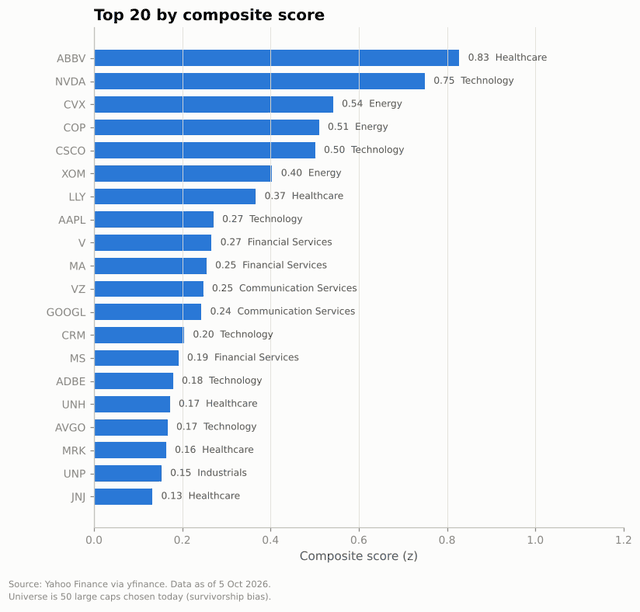

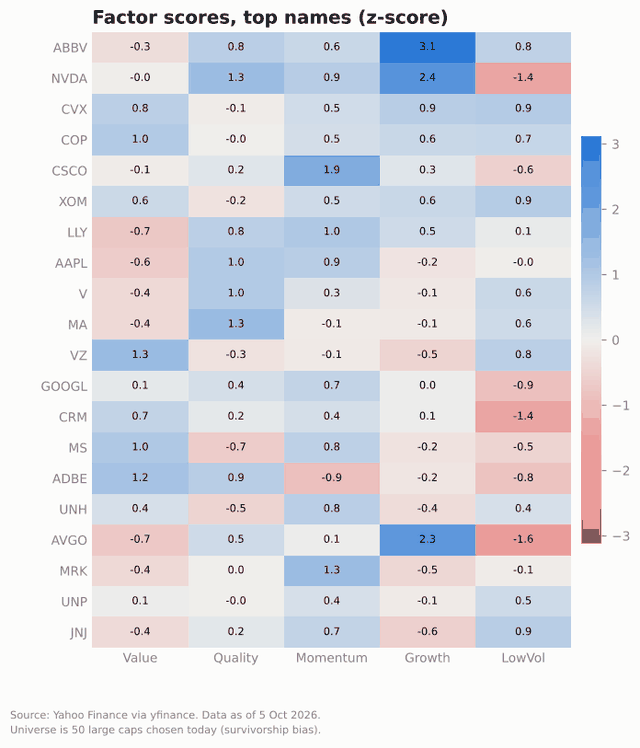

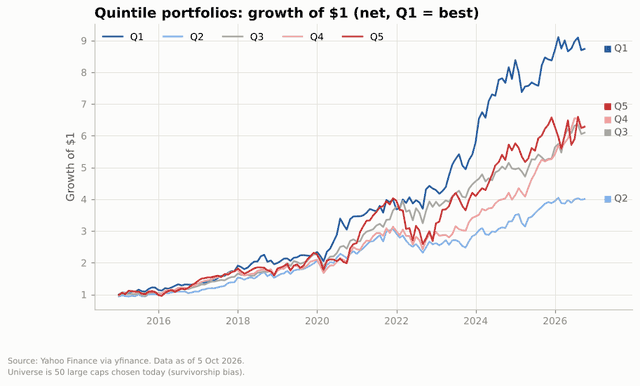

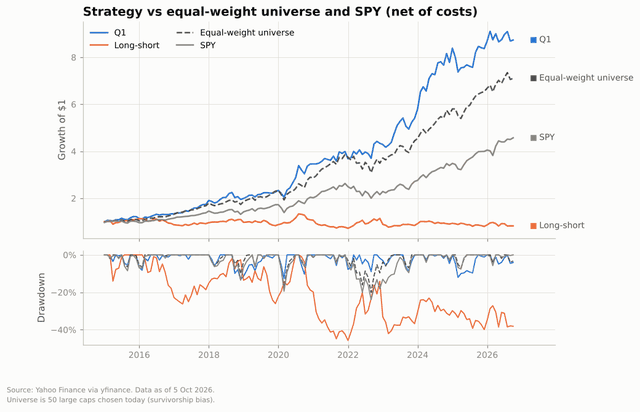

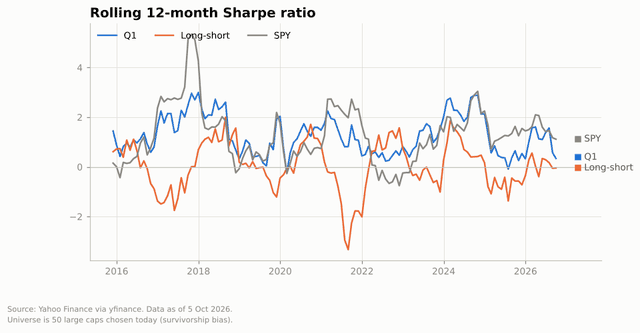

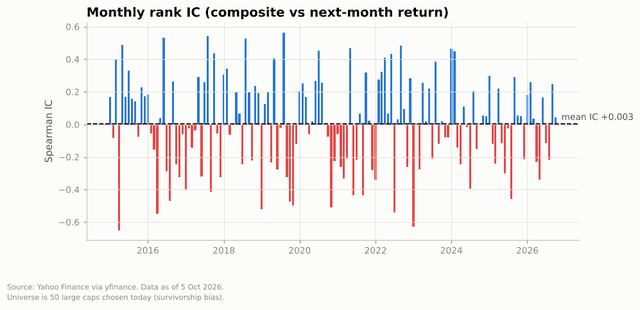

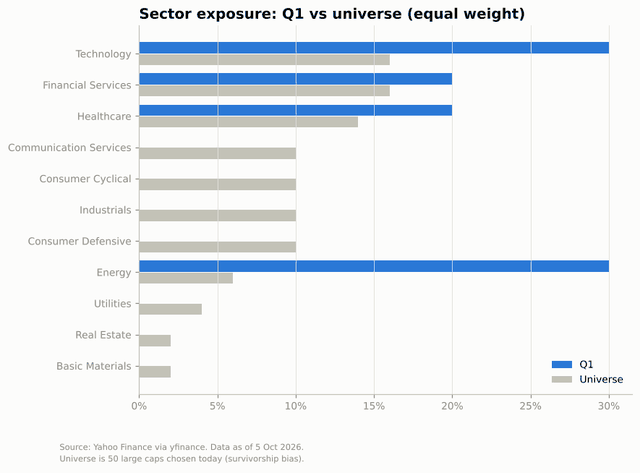

In [5]:
def show_small(path, width=640):
    im = PILImage.open(path).convert("RGB")
    im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.quantize(128).save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue()))


for p in visualization.make_all():
    show_small(p)

## 5. Single-stock report

The text profile shows everywhere. The two interactive Plotly figures render in Colab or Jupyter but not in GitHub's notebook preview.

In [6]:
show_report(stock_report("AAPL"))

AAPL - Apple Inc. (Technology)
Composite +0.27 | percentile 86 | quintile 1 | sector rank 3/8
Category z-scores: Value -0.62  Quality +0.97  Momentum +0.87  Growth -0.20  LowVol -0.04
              AAPL  SectorMedian
Ret1M        0.014         0.016
Ret6M        0.288         0.269
Ret12M       0.299         0.053
FCFYield     0.021         0.020
EV_EBITDA   30.116        18.641
Volatility   0.272         0.392
Beta         0.684         1.009
AAPL ranks in the 86th percentile of the 50-stock universe (quintile 1) and #3 of 8 in Technology. Its strongest factor is Quality (z = +0.97) and its weakest is Value (z = -0.62). This is a descriptive factor profile, not a recommendation.
